# Checking the SISSO equations of Yuan et al., *Mater. Today Phys.* 25 (2022) 100706
Run the cells in order. When Cell 1 asks, upload `seebeck_tableS1.csv`.

In [1]:
# ==== Cell 1: setup ====
import re, io, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression

# ---- Load data (Table S1 CSV) ----
try:
    from google.colab import files
    up = files.upload()                       # upload seebeck_tableS1.csv
    df = pd.read_csv(io.BytesIO(up[list(up)[0]]))
except ImportError:
    df = pd.read_csv("seebeck_tableS1.csv")
df.columns = ["compound", "n_1e18", "S_n", "S_p"]
print(df.shape); df.head()

Saving seebeck_tableS1.csv to seebeck_tableS1.csv
(910, 4)


,compound,n_1e18,S_n,S_p
0,TiSnPt,1,-562.0,679.0
1,ThSbRh,1,-538.0,531.0
2,ScAsNi,1,-649.0,521.0
3,ScSbPt,1,-634.0,540.0
4,NaAcTe2,1,-452.0,536.0


In [2]:
# ==== Cell 2: element properties (atomic number Z, Pauling electronegativity chi) ====
ELEM = {  # symbol: (Z, chi_Pauling)
 'Li':(3,0.98),'Be':(4,1.57),'B':(5,2.04),'N':(7,3.04),'Na':(11,0.93),'Mg':(12,1.31),'Al':(13,1.61),
 'Si':(14,1.90),'P':(15,2.19),'K':(19,0.82),'Ca':(20,1.00),'Sc':(21,1.36),'Ti':(22,1.54),'V':(23,1.63),
 'Cr':(24,1.66),'Mn':(25,1.55),'Fe':(26,1.83),'Co':(27,1.88),'Ni':(28,1.91),'Cu':(29,1.90),'Zn':(30,1.65),
 'Ga':(31,1.81),'Ge':(32,2.01),'As':(33,2.18),'Se':(34,2.55),'Rb':(37,0.82),'Sr':(38,0.95),'Y':(39,1.22),
 'Zr':(40,1.33),'Nb':(41,1.60),'Mo':(42,2.16),'Ru':(44,2.20),'Rh':(45,2.28),'Pd':(46,2.20),'Ag':(47,1.93),
 'Cd':(48,1.69),'In':(49,1.78),'Sn':(50,1.96),'Sb':(51,2.05),'Te':(52,2.10),'Cs':(55,0.79),'Ba':(56,0.89),
 'La':(57,1.10),'Tb':(65,1.10),'Dy':(66,1.22),'Ho':(67,1.23),'Er':(68,1.24),'Tm':(69,1.25),'Lu':(71,1.27),
 'Hf':(72,1.30),'Ta':(73,1.50),'W':(74,2.36),'Os':(76,2.20),'Ir':(77,2.20),'Pt':(78,2.28),'Au':(79,2.54),
 'Hg':(80,2.00),'Tl':(81,1.62),'Pb':(82,2.33),'Bi':(83,2.02),'Ac':(89,1.10),'Th':(90,1.30),
}

def parse(formula):
    """ABC (half-Heusler) or ABC2 (full-Heusler), in the order written in Table S1."""
    toks = re.findall(r'([A-Z][a-z]?)(\d*)', formula)
    assert len(toks) == 3, formula
    (A,nA),(B,nB),(C,nC) = [(e, int(k) if k else 1) for e,k in toks]
    return dict(A=A,B=B,C=C,NA=nA,NB=nB,NC=nC,
                ZA=ELEM[A][0],ZB=ELEM[B][0],ZC=ELEM[C][0],
                xA=ELEM[A][1],xB=ELEM[B][1],xC=ELEM[C][1])

feat = pd.DataFrame([parse(f) for f in df.compound])
d = pd.concat([df, feat], axis=1)
print(d[["compound","A","B","C","NA","NC"]].drop_duplicates().head(10))

  compound   A   B   C  NA  NC
0   TiSnPt  Ti  Sn  Pt   1   1
1   ThSbRh  Th  Sb  Rh   1   1
2   ScAsNi  Sc  As  Ni   1   1
3   ScSbPt  Sc  Sb  Pt   1   1
4  NaAcTe2  Na  Ac  Te   1   2
5   NbGaNi  Nb  Ga  Ni   1   1
6   ScSbPd  Sc  Sb  Pd   1   1
7  InAcTe2  In  Ac  Te   1   2
8   TiGeNi  Ti  Ge  Ni   1   1
9   NbSbRu  Nb  Sb  Ru   1   1


In [3]:
# ==== Cell 3: SISSO equations (Eqs. 1-8 of the paper) ====
# The paper does not state the unit of n inside ln(). Change here to test:
#   1.0 -> n in units of 1e18 cm^-3 (as in Table S1),  1e18 -> n in cm^-3,  0.1 -> n in 1e19 cm^-3
N_SCALE = 1.0
def sisso(d, scale=N_SCALE):
    n = d.n_1e18 * scale
    xA,xB,xC,ZA,ZB,ZC = d.xA,d.xB,d.xC,d.ZA,d.ZB,d.ZC
    Dn1 = np.log(n / xB * (ZB + ZC))
    Dn2 = np.abs((xA - xB) * np.log(xA) - np.abs(xA - np.abs(xA - xC)))
    Dn3 = np.abs(xB - np.abs(xA - xC) - np.abs(xC - np.abs(xB - xC)))
    Sn = 4.94e1*Dn1 + 4.09e2*Dn2 + 5.52e2*Dn3 - 7.76e2
    Dp1 = d.NA*np.log(n) + d.NC*np.exp(xA)
    Dp2 = np.abs(xC*np.abs(xA - xB) - (xA*xB)/np.log(ZC))
    with np.errstate(divide='ignore', invalid='ignore'):
        Dp3 = ((xC - xA)/np.abs(xB - xC)) / np.abs(xA/ZC - xB/ZB)
    Sp = -6.26e1*Dp1 - 1.45e3*Dp2 - 2.5e-2*Dp3 + 6.83e2
    return pd.DataFrame(dict(Dn1=Dn1,Dn2=Dn2,Dn3=Dn3,Sn_pred=Sn,Dp1=Dp1,Dp2=Dp2,Dp3=Dp3,Sp_pred=Sp))

d = pd.concat([d, sisso(d)], axis=1)

In [4]:
# ==== Cell 4: metrics ====
def metrics(y, yp, label):
    m = np.isfinite(y) & np.isfinite(yp)
    y, yp = y[m], yp[m]
    r = pearsonr(y, yp)[0]
    out = dict(set=label, N=len(y), Pearson_r=r, R2=r2_score(y, yp), r_squared=r**2,
               RMSE=np.sqrt(mean_squared_error(y, yp)), MAE=mean_absolute_error(y, yp),
               MedAE=np.median(np.abs(y-yp)), MaxAE=np.max(np.abs(y-yp)),
               Spearman=spearmanr(y, yp)[0], bias=np.mean(yp-y),
               sign_accuracy=np.mean(np.sign(y)==np.sign(yp)))
    return out

res = pd.DataFrame([metrics(d.S_n.values, d.Sn_pred.values, "n-type SISSO (paper coeffs)"),
                    metrics(d.S_p.values, d.Sp_pred.values, "p-type SISSO (paper coeffs)")])
print(res.round(3).to_string(index=False))
# NOTE: R2 (sklearn) measures agreement with the y=x line; r_squared = Pearson r^2 only
# measures linear correlation. The paper reports Pearson r (>0.8), not R2.

                        set   N  Pearson_r      R2  r_squared     RMSE      MAE   MedAE    MaxAE  Spearman      bias  sign_accuracy
n-type SISSO (paper coeffs) 854      0.428  -9.621      0.183  513.965  477.570 510.074 1262.229     0.426   472.606          0.116
p-type SISSO (paper coeffs) 907      0.459 -57.632      0.211 1394.202 1130.666 976.787 4735.245     0.496 -1130.029          0.163


In [5]:
# ==== Cell 5: sensitivity to the unit of n ====
rows = []
for s,lab in [(1.0,"n in 1e18 cm^-3"),(0.1,"n in 1e19 cm^-3"),(1e-2,"n in 1e20 cm^-3"),(1e18,"n in cm^-3")]:
    t = pd.concat([d[["S_n","S_p"]], sisso(d.iloc[:, :16], s)], axis=1)
    for typ in "np":
        mm = metrics(t[f"S_{typ}"].values, t[f"S{typ}_pred"].values, f"{typ}-type, {lab}")
        rows.append(mm)
print(pd.DataFrame(rows)[["set","N","Pearson_r","R2","RMSE","MAE"]].round(3).to_string(index=False))

                    set   N  Pearson_r       R2     RMSE      MAE
n-type, n in 1e18 cm^-3 854      0.428   -9.621  513.965  477.570
p-type, n in 1e18 cm^-3 907      0.459  -57.632 1394.202 1130.666
n-type, n in 1e19 cm^-3 854      0.428   -5.818  411.804  373.207
p-type, n in 1e19 cm^-3 907      0.459  -48.432 1280.159  990.475
n-type, n in 1e20 cm^-3 854      0.428   -3.056  317.620  282.034
p-type, n in 1e20 cm^-3 907      0.459  -40.486 1172.762  868.757
     n-type, n in cm^-3 854      0.428 -255.971 2528.147 2520.064
     p-type, n in cm^-3 907      0.459 -437.556 3813.049 3724.582


In [6]:
# ==== Cell 6: refit the linear coefficients on the same 3 descriptors (upper bound of this descriptor) ====
for typ, cols in [("n",["Dn1","Dn2","Dn3"]),("p",["Dp1","Dp2","Dp3"])]:
    t = d[cols+[f"S_{typ}"]].replace([np.inf,-np.inf],np.nan).dropna()
    lr = LinearRegression().fit(t[cols], t[f"S_{typ}"])
    print(f"{typ}-type refit coefs:", np.round(lr.coef_,4), "intercept:", round(lr.intercept_,2),
          "| R2 =", round(lr.score(t[cols], t[f'S_{typ}']),3))

n-type refit coefs: [ 48.0512  -8.9769 100.4806] intercept: -597.05 | R2 = 0.513
p-type refit coefs: [-15.6861 -72.4483  -0.0947] intercept: 492.55 | R2 = 0.328


In [7]:
# ==== Cell 7: per-carrier-concentration metrics ====
per = []
for n, g in d.groupby("n_1e18"):
    for typ in "np":
        m = metrics(g[f"S_{typ}"].values, g[f"S{typ}_pred"].values, f"{typ}")
        m["n (1e18 cm^-3)"] = n; per.append(m)
print(pd.DataFrame(per)[["n (1e18 cm^-3)","set","N","Pearson_r","R2","RMSE","MAE"]].round(3).to_string(index=False))

 n (1e18 cm^-3) set   N  Pearson_r       R2     RMSE      MAE
              1   n 136      0.229   -7.584  559.531  498.672
              1   p 140      0.375  -49.121 1403.180 1155.588
              5   n  68      0.110  -11.358  511.473  469.611
              5   p  73      0.555  -82.346 1373.656 1106.054
              7   n  70      0.101  -13.358  512.159  472.656
              7   p  74      0.588  -95.714 1378.883 1114.977
             10   n  76      0.170  -13.608  507.768  472.818
             10   p  82      0.600  -97.079 1367.266 1122.213
             30   n  71      0.098  -22.346  497.190  464.592
             30   p  75      0.665 -164.366 1388.255 1122.107
             50   n  71      0.121  -28.887  494.910  464.941
             50   p  75      0.677 -182.475 1385.882 1117.685
             70   n  71      0.143  -34.760  493.843  465.457
             70   p  75      0.674 -205.253 1387.204 1116.535
            100   n  79      0.182  -32.131  497.946  470.675
        

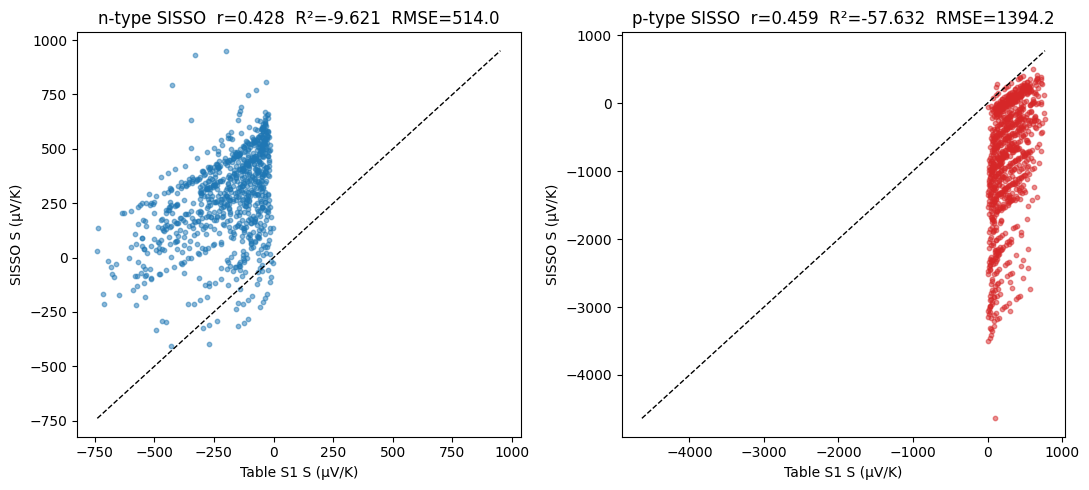

In [8]:
# ==== Cell 8: parity plots ====
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, typ, c in [(ax[0],"n","tab:blue"),(ax[1],"p","tab:red")]:
    y, yp = d[f"S_{typ}"], d[f"S{typ}_pred"]
    a.scatter(y, yp, s=10, alpha=.5, c=c)
    lo, hi = np.nanmin([y.min(), yp.min()]), np.nanmax([y.max(), yp.max()])
    a.plot([lo,hi],[lo,hi],"k--",lw=1)
    r = res.iloc[0 if typ=="n" else 1]
    a.set_title(f"{typ}-type SISSO  r={r.Pearson_r:.3f}  R²={r.R2:.3f}  RMSE={r.RMSE:.1f}")
    a.set_xlabel("Table S1 S (μV/K)"); a.set_ylabel("SISSO S (μV/K)")
plt.tight_layout(); plt.show()

In [9]:
# ==== Cell 9: worst predictions ====
d["err_n"] = d.Sn_pred - d.S_n; d["err_p"] = d.Sp_pred - d.S_p
print(d.reindex(d.err_n.abs().sort_values(ascending=False).index)[["compound","n_1e18","S_n","Sn_pred","err_n"]].head(10))
print(d.reindex(d.err_p.abs().sort_values(ascending=False).index)[["compound","n_1e18","S_p","Sp_pred","err_p"]].head(10))
d.to_csv("sisso_predictions.csv", index=False)

    compound  n_1e18    S_n     Sn_pred        err_n
36     LiMgN       1 -330.0  932.229186  1262.229186
63    NaBiLi       1 -424.0  791.198999  1215.198999
51     LiZnN       1 -201.0  950.944898  1151.944898
132   NaNLi2       1 -347.0  634.434160   981.434160
109   TiAsCo       1 -734.0  135.105338   869.105338
762  HgPbCa2     300 -106.0  747.008694   853.008694
120  TlSbNa2       1 -346.0  503.473440   849.473440
835  HgPbCa2     500  -72.0  772.243480   844.243480
159   TiPbNi       5 -472.0  371.407287   843.407287
902  HgPbCa2    1000  -31.0  806.484950   837.484950
    compound  n_1e18    S_p      Sp_pred        err_p
39   GaSbLi2       1   97.0 -4638.245425 -4735.245425
904  AuAsCa2    1000    7.0 -3494.510898 -3501.510898
823  AuAsCa2     500   30.0 -3451.119885 -3481.119885
750  AuAsCa2     300   46.0 -3419.142201 -3465.142201
679  AuAsCa2     100   65.0 -3350.369071 -3415.369071
119  AuAsCa2       1  308.0 -3062.085418 -3370.085418
581  AuAsCa2      70   41.0 -3328.04122

In [10]:
# ==== Cell 10: diagnostic - try every A/B/C site assignment ====
import itertools
base = d[["compound","n_1e18","S_n","S_p","NA","NB","NC","ZA","ZB","ZC","xA","xB","xC"]].copy()
out = []
for p in itertools.permutations("ABC"):
    t = base.copy()
    for new, old in zip("ABC", p):
        for k in ["Z","x","N"]: t[k+new] = base[k+old]
    o = sisso(t)
    mn = metrics(t.S_n.values, o.Sn_pred.values, "")
    mp = metrics(t.S_p.values, o.Sp_pred.values, "")
    out.append(dict(order="".join(p), r_n=mn["Pearson_r"], RMSE_n=mn["RMSE"], r_p=mp["Pearson_r"], RMSE_p=mp["RMSE"]))
print(pd.DataFrame(out).round(3).to_string(index=False))

order   r_n  RMSE_n   r_p       RMSE_p
  ABC 0.428 513.965 0.459 1.394202e+03
  ACB 0.281 554.820 0.374 1.667182e+03
  BAC 0.435 528.907 0.075 8.087680e+12
  BCA 0.276 745.209 0.066 8.977325e+13
  CAB 0.289 484.327 0.375 1.764628e+03
  CBA 0.043 719.889 0.322 2.142829e+03
